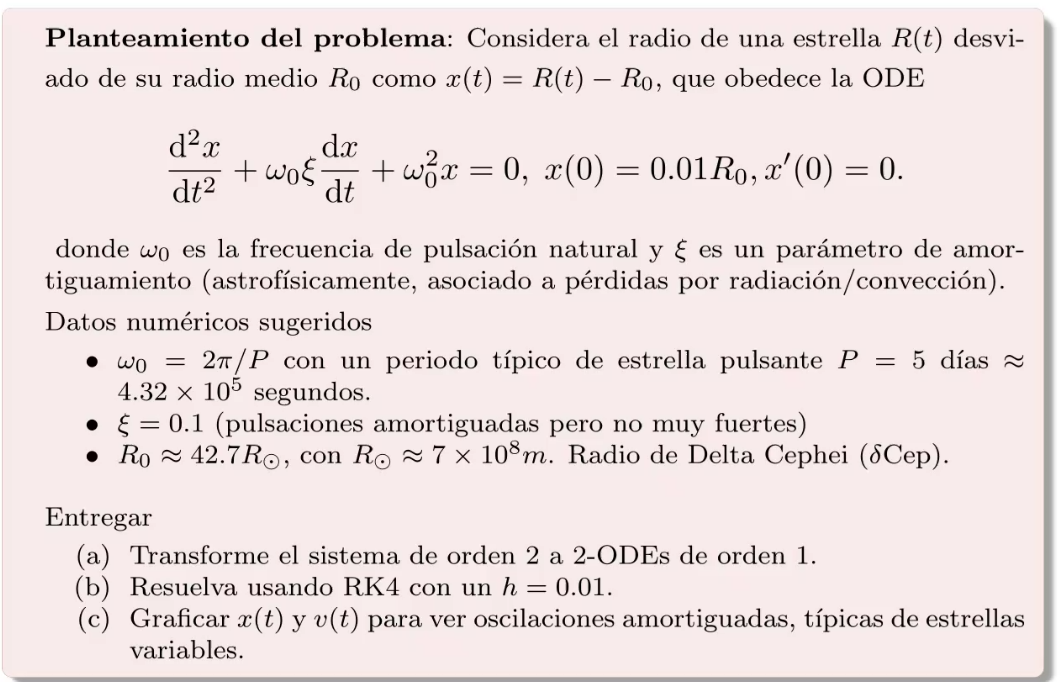

a)

Definimos dos variables nuevas:
$$x_1(t) = x(t)$$ 

La posición o desviación del radio
$$x_2(t) = \frac{dx}{dt} = v(t)$$

La velocidad de pulsación. Sustituyendo estas definiciones en la ecuación original y despejando la derivada más alta, obtenemos nuestro sistema acoplado:
$$\frac{dx_1}{dt} = x_2$$ $$\frac{dx_2}{dt} = -\omega_0 \xi x_2 - \omega_0^2 x_1$$

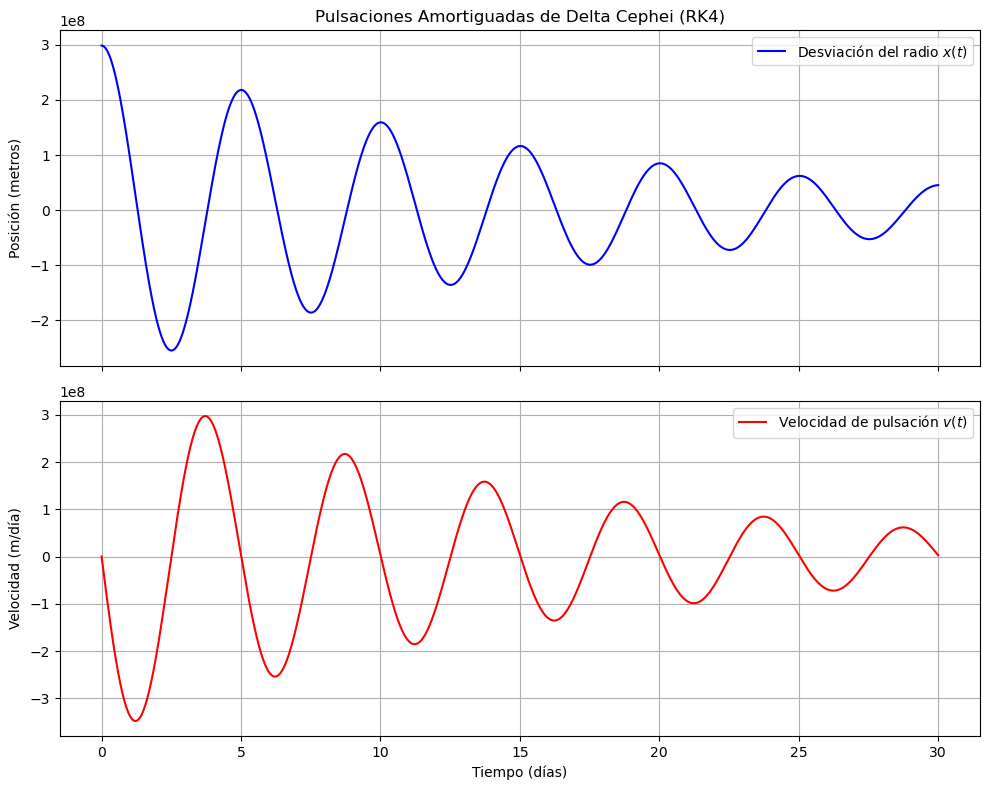

In [4]:
#Eduardo Perez
import numpy as np
import matplotlib.pyplot as plt

#Physical constants
P = 5.0
omega_0 = (2*np.pi)/P
xi, R_sun = 0.1, 7e8
R_0 = 42.7*R_sun

#Simulation params
h, t_final = 0.01, 30.0
t = np.arange(0, t_final+h,h)

#Arrays to save data
N = len(t)
x_vals = np.zeros(N)
v_vals = np.zeros(N)

#Initial conditions
x_vals[0] = 0.01*R_0
v_vals[0] = 0.0

def system_ode(x_pos, v_vel):
    dx_dt = v_vel
    dv_dt = -omega_0*xi*v_vel-(omega_0**2)*x_pos
    return dx_dt, dv_dt

#RK4 method
for i in range(N-1):
    x_current = x_vals[i]
    v_current = v_vals[i]

    k1_x, k1_v = system_ode(x_current,v_current)
    k2_x, k2_v = system_ode(x_current + 0.5*h*k1_x, v_current + 0.5*h*k1_v)
    k3_x, k3_v = system_ode(x_current + 0.5*h*k2_x, v_current + 0.5*h*k2_v)
    k4_x, k4_v = system_ode(x_current + h*k3_x, v_current + h*k3_v)

    x_vals[i+1] = x_current + (h/6.0)*(k1_x + 2*k2_x + 2*k3_x + k4_x)
    v_vals[i+1] = v_current + (h/6.0)*(k1_v + 2*k2_v + 2*k3_v + k4_v)
    
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Gráfica de x(t) - Posición
ax1.plot(t, x_vals, color='blue', label='Desviación del radio $x(t)$')
ax1.set_ylabel('Posición (metros)')
ax1.set_title('Pulsaciones Amortiguadas de Delta Cephei (RK4)')
ax1.grid(True)
ax1.legend()

# Gráfica de v(t) - Velocidad
ax2.plot(t, v_vals, color='red', label='Velocidad de pulsación $v(t)$')
ax2.set_xlabel('Tiempo (días)')
ax2.set_ylabel('Velocidad (m/día)')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

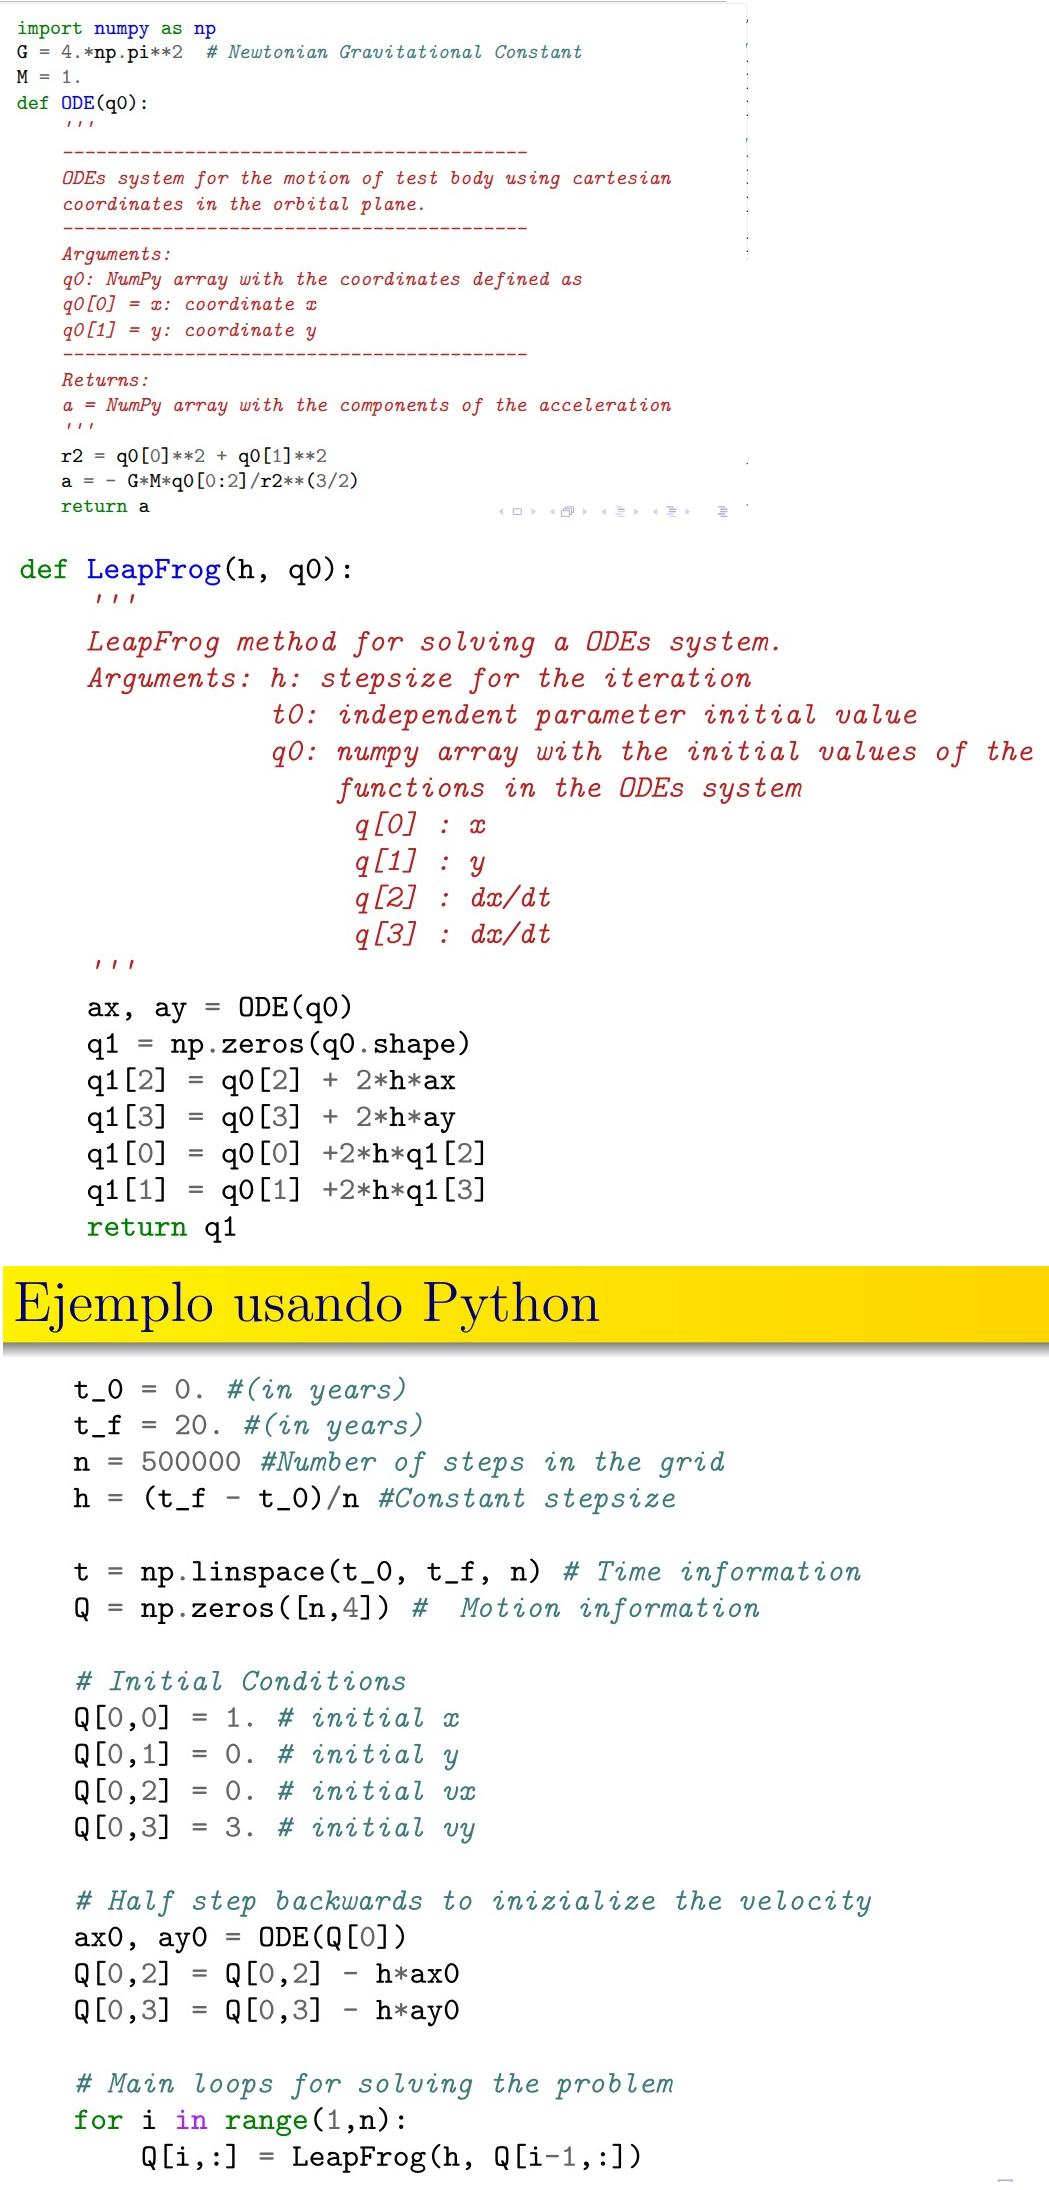


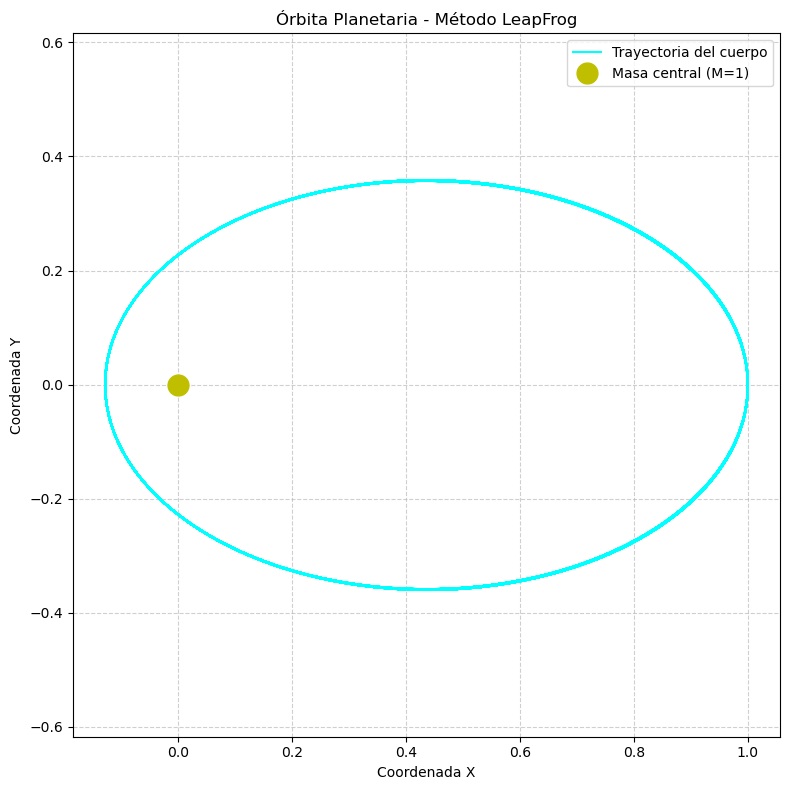

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Newtonian Gravitational Constant
G = 4. * np.pi**2 
M = 1.

def Ode(Q0):
    '''
    ----------------------------------------------------
    ODEs system for the motion of test body using cartesian
    coordinates in the orbital plane.
    ----------------------------------------------------
    Arguments:
    Q0: NumPy array with the coordinates defined as
    Q0[0] = x: coordinate x
    Q0[1] = y: coordinate y
    ----------------------------------------------------
    Returns:
    A = NumPy array with the components of the acceleration
    '''
    R2 = Q0[0]**2 + Q0[1]**2
    A = -G * M * Q0[0:2] / R2**(3/2)
    return A

def LeapFrog(H, Q0):
    '''
    LeapFrog method for solving a ODEs system.
    Arguments: H: stepsize for the iteration
               Q0: numpy array with the initial values of the
                   functions in the ODEs system
                   Q0[0] : x
                   Q0[1] : y
                   Q0[2] : dx/dt
                   Q0[3] : dy/dt 
    '''
    Ax, Ay = Ode(Q0)
    Q1 = np.zeros(Q0.shape)
    
    # Velocity update
    Q1[2] = Q0[2] + 2 * H * Ax
    Q1[3] = Q0[3] + 2 * H * Ay
    
    # Position update
    Q1[0] = Q0[0] + 2 * H * Q1[2]
    Q1[1] = Q0[1] + 2 * H * Q1[3]
    
    return Q1

# --- Main Example (Transcribed from image) ---

T0 = 0.         # (in years)
TF = 20.        # (in years)
N = 500000      # Number of steps in the grid
H = (TF - T0)/N # Constant stepsize

T = np.linspace(T0, TF, N) # Time information
Q = np.zeros([N, 4])       # Motion information

# Initial Conditions
Q[0, 0] = 1. # initial x
Q[0, 1] = 0. # initial y
Q[0, 2] = 0. # initial vx
Q[0, 3] = 3. # initial vy

# Half step backwards to initialize the velocity
Ax0, Ay0 = Ode(Q[0])
Q[0, 2] = Q[0, 2] - H * Ax0
Q[0, 3] = Q[0, 3] - H * Ay0

# Main loops for solving the problem
for I in range(1, N):
    Q[I, :] = LeapFrog(H, Q[I-1, :])

# --- Plotting the Orbit (New Code) ---

Fig, AxFig = plt.subplots(figsize=(8, 8))

# Plot the calculated orbit
AxFig.plot(Q[:, 0], Q[:, 1], color='cyan', label='Trayectoria del cuerpo')

# Plot the central mass (e.g., a star) at the origin
AxFig.plot(0, 0, 'yo', markersize=15, label='Masa central (M=1)')

# Plot configuration
AxFig.set_xlabel('Coordenada X')
AxFig.set_ylabel('Coordenada Y')
AxFig.set_title('Órbita Planetaria - Método LeapFrog')
AxFig.grid(True, linestyle='--', alpha=0.6)
AxFig.axis('equal') # Critical: Ensures the aspect ratio is 1:1 so circles don't look like ovals
AxFig.legend()

plt.tight_layout()
plt.show()
#Eduardo Perez

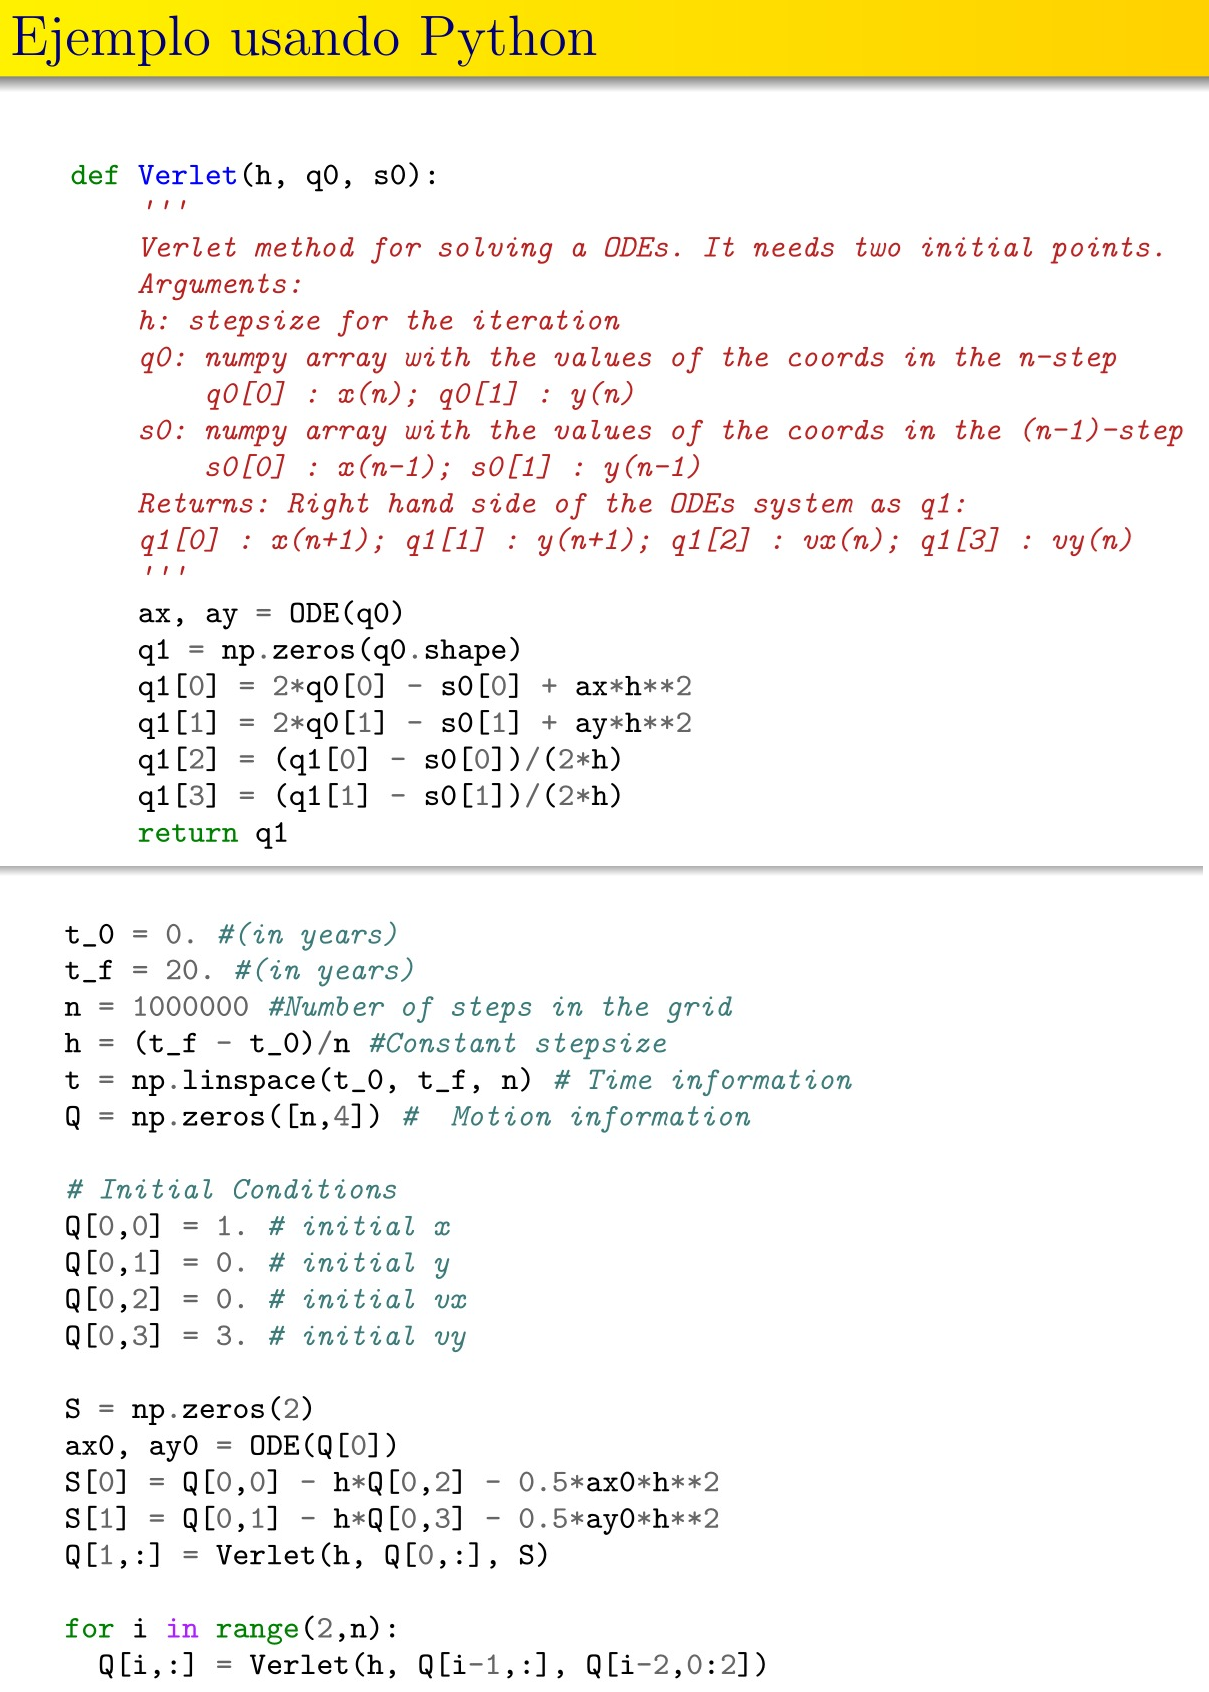

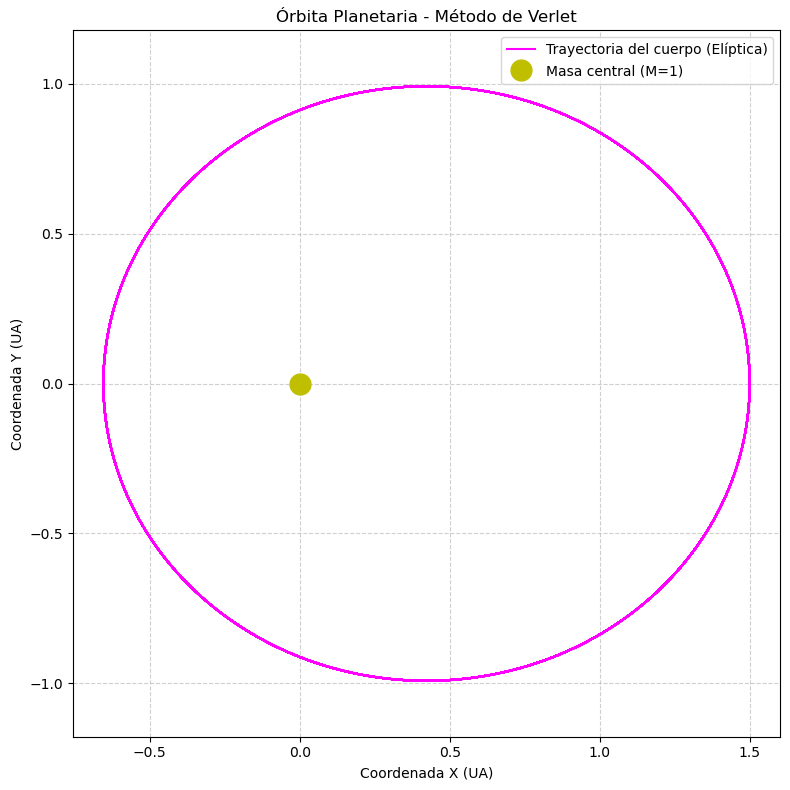

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Newtonian Gravitational Constant
G = 4. * np.pi**2 
M = 1.

def Ode(Q0):
    '''
    ODEs system for the motion of test body using cartesian
    coordinates in the orbital plane.
    '''
    R2 = Q0[0]**2 + Q0[1]**2
    A = -G * M * Q0[0:2] / R2**(3/2)
    return A

def Verlet(H, Q0, S0):
    '''
    Verlet method for solving ODEs. It needs two initial points.
    Arguments:
    H: stepsize for the iteration
    Q0: numpy array with the values of the coords in the n-step
        Q0[0] : x(n); Q0[1] : y(n)
    S0: numpy array with the values of the coords in the (n-1)-step
        S0[0] : x(n-1); S0[1] : y(n-1)
    Returns: Right hand side of the ODEs system as Q1:
    Q1[0] : x(n+1); Q1[1] : y(n+1); Q1[2] : vx(n); Q1[3] : vy(n)
    '''
    Ax, Ay = Ode(Q0)
    Q1 = np.zeros(Q0.shape)
    
    # Position update based on current and previous step
    Q1[0] = 2 * Q0[0] - S0[0] + Ax * H**2
    Q1[1] = 2 * Q0[1] - S0[1] + Ay * H**2
    
    # Velocity calculation using central difference
    Q1[2] = (Q1[0] - S0[0]) / (2 * H)
    Q1[3] = (Q1[1] - S0[1]) / (2 * H)
    
    return Q1

# --- Main Example ---

T0 = 0.         # (in years)
TF = 20.        # (in years)
N = 1000000     # Number of steps in the grid (Increased to 1M)
H = (TF - T0) / N # Constant stepsize

T = np.linspace(T0, TF, N) # Time information
Q = np.zeros([N, 4])       # Motion information

# Altered Initial Conditions (Modified to see orbit variation)
Q[0, 0] = 1.5 # initial x (Original: 1.0)
Q[0, 1] = 0.  # initial y
Q[0, 2] = 0.  # initial vx
Q[0, 3] = 4.0 # initial vy (Original: 3.0)

# Initialize array for (n-1)-step (S array)
S = np.zeros(2)

# Calculate initial acceleration
Ax0, Ay0 = Ode(Q[0])

# Backwards Euler/Taylor approximation to find the "previous" position S
S[0] = Q[0, 0] - H * Q[0, 2] - 0.5 * Ax0 * H**2
S[1] = Q[0, 1] - H * Q[0, 3] - 0.5 * Ay0 * H**2

# First step requires Q[0] and our backwards-calculated S
Q[1, :] = Verlet(H, Q[0, :], S)

# Main loops for solving the problem starting from step 2
for I in range(2, N):
    Q[I, :] = Verlet(H, Q[I-1, :], Q[I-2, 0:2])

# --- Plotting the Orbit ---

Fig, AxFig = plt.subplots(figsize=(8, 8))

# Plot the calculated orbit
AxFig.plot(Q[:, 0], Q[:, 1], color='magenta', label='Trayectoria del cuerpo (Elíptica)')

# Plot the central mass
AxFig.plot(0, 0, 'yo', markersize=15, label='Masa central (M=1)')

# Plot configuration
AxFig.set_xlabel('Coordenada X (UA)')
AxFig.set_ylabel('Coordenada Y (UA)')
AxFig.set_title('Órbita Planetaria - Método de Verlet')
AxFig.grid(True, linestyle='--', alpha=0.6)
AxFig.axis('equal') # Maintains 1:1 aspect ratio
AxFig.legend()

plt.tight_layout()
plt.show()

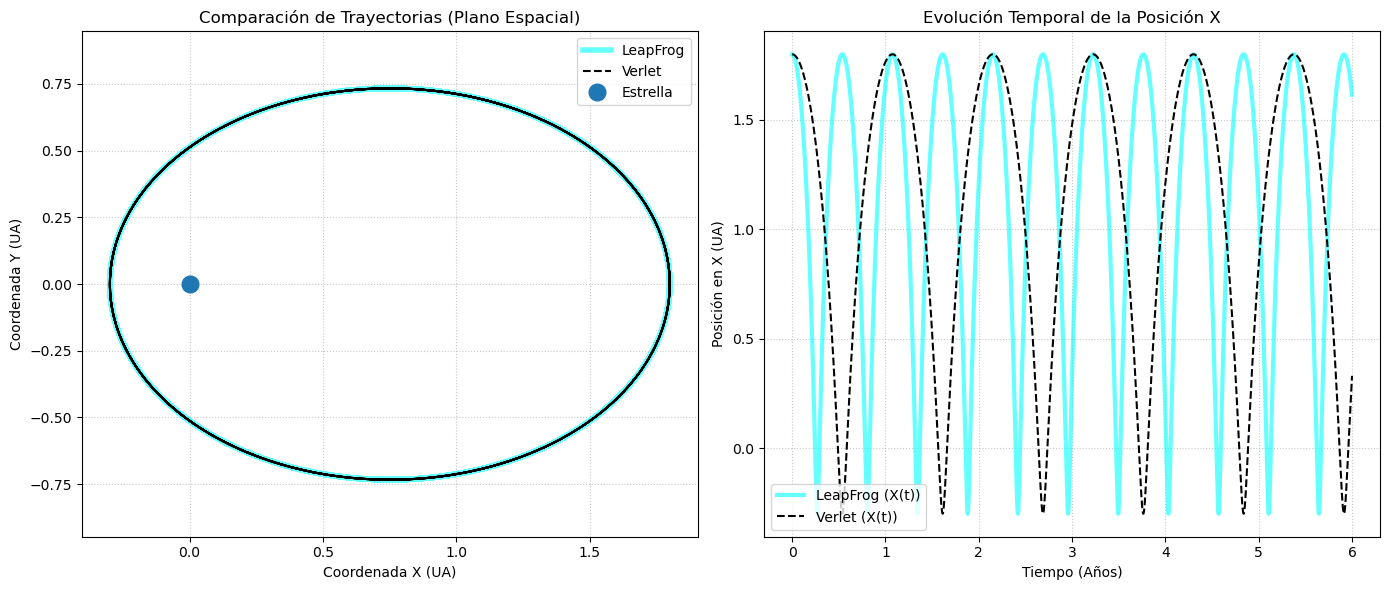

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Newtonian Gravitational Constant and Central Mass
G = 4. * np.pi**2 
M = 1.

def Ode(Q0):
    '''
    Calculates gravitational acceleration based on position.
    '''
    R2 = Q0[0]**2 + Q0[1]**2
    A = -G * M * Q0[0:2] / R2**(1.5)
    return A

def LeapFrog(H, Q0):
    '''
    LeapFrog integration (using 2*H as dictated by the theoretical material).
    '''
    Ax, Ay = Ode(Q0)
    Q1 = np.zeros(4)
    
    Q1[2] = Q0[2] + 2 * H * Ax
    Q1[3] = Q0[3] + 2 * H * Ay
    
    Q1[0] = Q0[0] + 2 * H * Q1[2]
    Q1[1] = Q0[1] + 2 * H * Q1[3]
    
    return Q1

def Verlet(H, Q0, S0):
    '''
    Verlet integration using current and previous steps.
    '''
    Ax, Ay = Ode(Q0)
    Q1 = np.zeros(4)
    
    Q1[0] = 2 * Q0[0] - S0[0] + Ax * H**2
    Q1[1] = 2 * Q0[1] - S0[1] + Ay * H**2
    
    Q1[2] = (Q1[0] - S0[0]) / (2 * H)
    Q1[3] = (Q1[1] - S0[1]) / (2 * H)
    
    return Q1

# --- Simulation Setup ---
T0 = 0.         
TF = 6.         # Simulating 6 years to capture multiple orbits
N = 500000      
H = (TF - T0) / N 
T = np.linspace(T0, TF, N) 

QLF = np.zeros([N, 4])  # LeapFrog Data
QV = np.zeros([N, 4])   # Verlet Data

# Highly Elliptical Initial Conditions (Further away, slower tangential velocity)
InitConditions = [1.8, 0.0, 0.0, 2.5]
QLF[0, :] = InitConditions
QV[0, :] = InitConditions

# --- LeapFrog Initialization ---
Ax0, Ay0 = Ode(QLF[0])
QLF[0, 2] = QLF[0, 2] - H * Ax0
QLF[0, 3] = QLF[0, 3] - H * Ay0

# --- Verlet Initialization ---
S = np.zeros(2)
S[0] = QV[0, 0] - H * QV[0, 2] - 0.5 * Ax0 * H**2
S[1] = QV[0, 1] - H * QV[0, 3] - 0.5 * Ay0 * H**2
QV[1, :] = Verlet(H, QV[0], S)

# --- Main Iteration Loop ---
for I in range(1, N):
    QLF[I, :] = LeapFrog(H, QLF[I-1, :])

for I in range(2, N):
    QV[I, :] = Verlet(H, QV[I-1, :], QV[I-2, 0:2])

# --- Comparative Plotting ---
Fig, (Ax1, Ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Orbital Trajectory (X vs Y)
Ax1.plot(QLF[:, 0], QLF[:, 1], color='cyan', linewidth=4, alpha=0.6, label='LeapFrog')
Ax1.plot(QV[:, 0], QV[:, 1], color='black', linestyle='--', linewidth=1.5, label='Verlet')
Ax1.plot(0, 0, 'o', markersize=12, label='Estrella')
Ax1.set_xlabel('Coordenada X (UA)')
Ax1.set_ylabel('Coordenada Y (UA)')
Ax1.set_title('Comparación de Trayectorias (Plano Espacial)')
Ax1.grid(True, linestyle=':', alpha=0.7)
Ax1.axis('equal') 
Ax1.legend()

# Subplot 2: X-Coordinate over Time (Phase difference)
Ax2.plot(T, QLF[:, 0], color='cyan', linewidth=3, alpha=0.6, label='LeapFrog (X(t))')
Ax2.plot(T, QV[:, 0], color='black', linestyle='--', linewidth=1.5, label='Verlet (X(t))')
Ax2.set_xlabel('Tiempo (Años)')
Ax2.set_ylabel('Posición en X (UA)')
Ax2.set_title('Evolución Temporal de la Posición X')
Ax2.grid(True, linestyle=':', alpha=0.7)
Ax2.legend()

plt.tight_layout()
plt.show()
#Eduado Perez

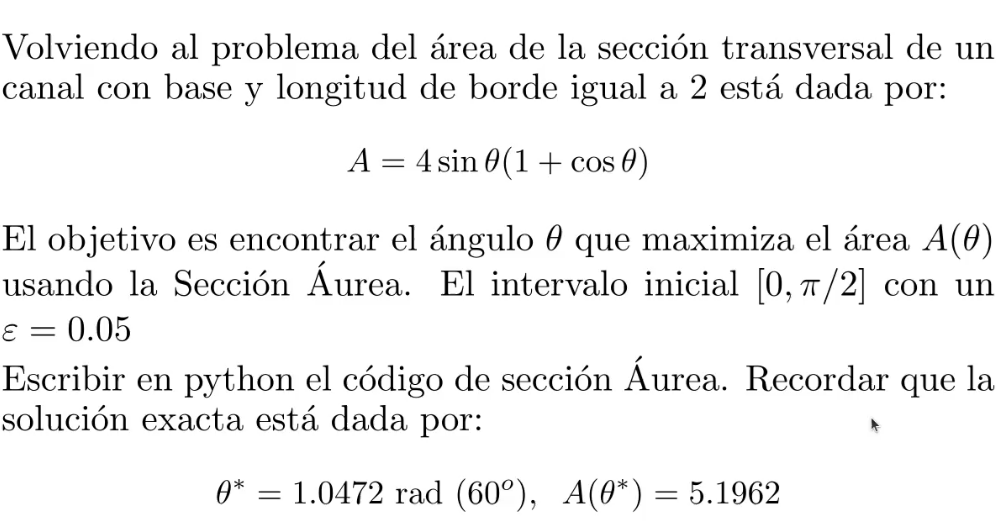

In [13]:
import math

thetaExact = 1.0472
areaExact = 5.1962

def Area(Theta):
    return 4 * math.sin(Theta) * (1 + math.cos(Theta))

xL, xU, epsilon = 0.0, math.pi / 2.0, 0.05
phi = (math.sqrt(5) - 1) / 2.0

D = phi * (xU - xL)
x1, x2 = xL + D, xU - D

f1, f2 = Area(x1), Area(x2)

iteration = 0

print(f"{'Iter':>4} | {'Xl':>8} | {'Xu':>8} | {'Theta Óptimo':>12} | {'Err Verd. (rad)':>15} | {'Err Rel (%)':>11}")
print("-" * 80)

while abs(xU - xL) >= epsilon:
    iteration += 1
    if f1 > f2:
        xL = x2 
        x2 = x1
        f2 = f1
        
        D = phi * (xU - xL)
        x1 = xL + D
        f1 = Area(x1)
    else:
        xU = x1
        x1 = x2
        f1 = f2
        
        D = phi * (xU - xL)
        x2 = xU - D
        f2 = Area(x2)
        
    thetaOpt = (xL + xU) / 2.0
    trueError = abs(thetaExact - thetaOpt)
    relError = (trueError / thetaExact) * 100
    
    print(f"{iteration:4} | {xL:8.4f} | {xU:8.4f} | {thetaOpt:12.4f} | {trueError:15.6f} | {relError:11.4f}")

thetaFinal = (xL + xU) / 2.0
areaFinal = Area(thetaFinal)
finalTrueError = abs(thetaExact - thetaFinal)
finalRelError = (finalTrueError / thetaExact) * 100

print("-" * 80)
print(f"Solución alcanzada en la iteración : {iteration}")
print(f"Ángulo óptimo encontrado (Theta)   : {thetaFinal:.4f} rad")
print(f"Área máxima calculada (A)          : {areaFinal:.4f}")
print(f"Error Verdadero Final              : {finalTrueError:.6f} rad")
print(f"Error Relativo Final               : {finalRelError:.4f} %")
#Eduardo Perez

Iter |       Xl |       Xu | Theta Óptimo | Err Verd. (rad) | Err Rel (%)
--------------------------------------------------------------------------------
   1 |   0.6000 |   1.5708 |       1.0854 |        0.038194 |      3.6472
   2 |   0.6000 |   1.2000 |       0.9000 |        0.147214 |     14.0578
   3 |   0.8292 |   1.2000 |       1.0146 |        0.032626 |      3.1155
   4 |   0.9708 |   1.2000 |       1.0854 |        0.038194 |      3.6472
   5 |   0.9708 |   1.1124 |       1.0416 |        0.005575 |      0.5324
   6 |   1.0249 |   1.1124 |       1.0687 |        0.021475 |      2.0507
   7 |   1.0249 |   1.0790 |       1.0520 |        0.004757 |      0.4543
   8 |   1.0249 |   1.0583 |       1.0416 |        0.005575 |      0.5324
--------------------------------------------------------------------------------
Solución alcanzada en la iteración : 8
Ángulo óptimo encontrado (Theta)   : 1.0416 rad
Área máxima calculada (A)          : 5.1960
Error Verdadero Final              : 0.00

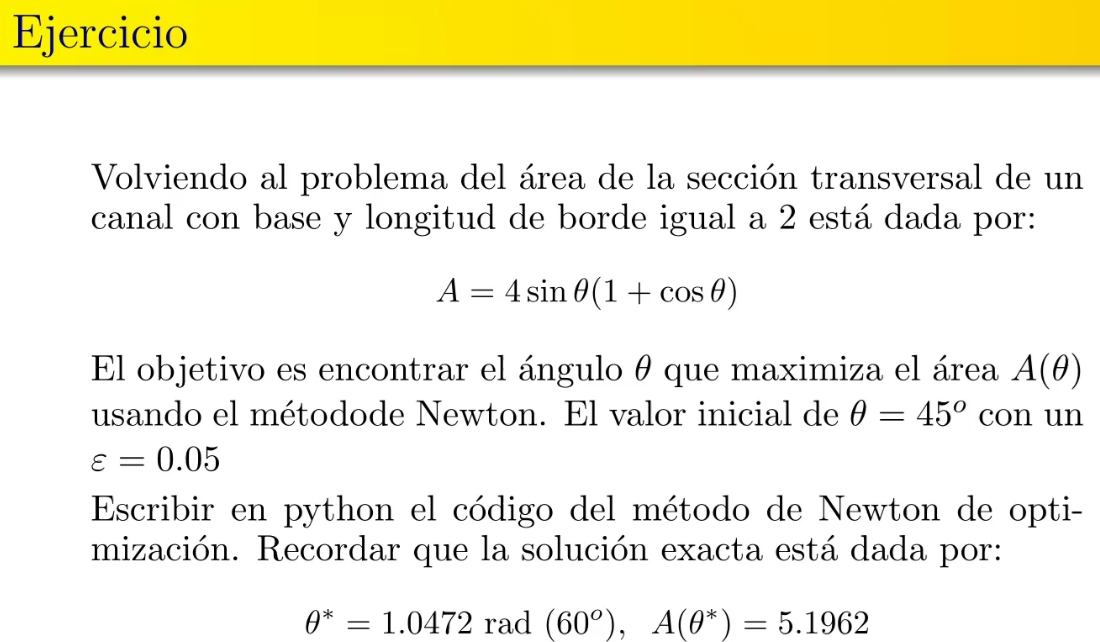

In [14]:
import math

# Exact values provided for error calculation
ThetaExact = 1.0472
AreaExact = 5.1962

# Objective function A(Theta)
def Area(Theta):
    return 4 * math.sin(Theta) * (1 + math.cos(Theta))

# First derivative of the objective function (A')
def D1Area(Theta):
    return 4 * math.cos(Theta) + 4 * math.cos(2 * Theta)

# Second derivative of the objective function (A'')
def D2Area(Theta):
    return -4 * math.sin(Theta) - 8 * math.sin(2 * Theta)

# Initial parameters
Theta0 = math.pi / 4.0      # 45 degrees in radians
Epsilon = 0.05              # Tolerance %
ThetaCurrent = Theta0
Iteration = 0
ApproxError = 100.0         # Initialized high to enter the loop

print(f"{'Iter':>4} | {'Theta Actual':>12} | {'Theta Nuevo':>12} | {'Err Aprox (%)':>13} | {'Err Verd. (rad)':>15}")
print("-" * 65)

# Main loop for Newton's Optimization Method
while ApproxError >= Epsilon:
    Iteration += 1
    
    # Newton's optimization formula: x_new = x_old - f'(x_old) / f''(x_old)
    ThetaNew = ThetaCurrent - (D1Area(ThetaCurrent) / D2Area(ThetaCurrent))
    
    # Calculate relative approximate error percentage
    ApproxError = abs((ThetaNew - ThetaCurrent) / ThetaNew) * 100
    
    # True absolute error in radians
    TrueError = abs(ThetaExact - ThetaNew)
    
    print(f"{Iteration:4} | {ThetaCurrent:12.4f} | {ThetaNew:12.4f} | {ApproxError:13.4f} | {TrueError:15.6f}")
    
    # Update for next iteration
    ThetaCurrent = ThetaNew

# Final results extraction
AreaFinal = Area(ThetaCurrent)
FinalTrueError = abs(ThetaExact - ThetaCurrent)
FinalRelError = (FinalTrueError / ThetaExact) * 100

print("-" * 65)
print(f"Solución alcanzada en la iteración : {Iteration}")
print(f"Ángulo óptimo encontrado (Theta)   : {ThetaCurrent:.4f} rad")
print(f"Área máxima calculada (A)          : {AreaFinal:.4f}")
print(f"Error Verdadero Final              : {FinalTrueError:.6f} rad")
print(f"Error Relativo Verdadero Final     : {FinalRelError:.4f} %")

Iter | Theta Actual |  Theta Nuevo | Err Aprox (%) | Err Verd. (rad)
-----------------------------------------------------------------
   1 |       0.7854 |       1.0466 |       24.9573 |        0.000598
   2 |       1.0466 |       1.0472 |        0.0569 |        0.000003
   3 |       1.0472 |       1.0472 |        0.0000 |        0.000002
-----------------------------------------------------------------
Solución alcanzada en la iteración : 3
Ángulo óptimo encontrado (Theta)   : 1.0472 rad
Área máxima calculada (A)          : 5.1962
Error Verdadero Final              : 0.000002 rad
Error Relativo Verdadero Final     : 0.0002 %
